In [1]:
## Run from scvi environment
## Need specific scanpy versions to be able to properly read cellbender formats

In [2]:
import os
import sys
import math
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import anndata as ad
import session_info

In [3]:
session_info.show()

/software/conda/users/od5/scvi_24/lib/python3.9/site-packages/session_info/main.py:213: UserWarning: The '__version__' attribute is deprecated and will be removed in MarkupSafe 3.1. Use feature detection, or `importlib.metadata.version("markupsafe")`, instead.
  mod_version = _find_version(mod.__version__)


In [5]:
work_dir = '/lustre/scratch125/casm/teams/team215/users/od5/projects/celltherapy/ipsc/multiome/tf_barcodes/'
os.makedirs(work_dir , exist_ok=True)

In [6]:
## Read metadata table (library level)
sample_metad = pd.read_csv('/nfs/casm/team215mg/users/od5/projects/celltherapy/ipsc/multiome/tf_pilot/001_preprocessing/immnk_by_sample_manifest_updated - immnk_20251028.csv')

In [7]:
sample_metad

,run_ID,run_date,enrichment,sort_type,sample_type,study,sample_ID,sample_GEX,sample_GEX_2,sample_ATAC,...,cell_calling_mode,markerGenes,souporcell_run_ID,souporcell_K,souporcell_dir,cellbender_dir,n_cells_targeted,n_cells_cellranger,sample_description,comments
0,run_001,3/4/2024,total,NaN,kolf2_derived_nk_cells,ImmNK,multi_Imm_NK14825633,Imm_NK14825633,NaN,Imm_NK14826113,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_001,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,NKdiff_batch1_ day20,NaN
1,run_002,16/4/2024,total,NaN,kolf2_derived_nk_cells,ImmNK,multi_Imm_NK14825634,Imm_NK14825634,NaN,Imm_NK14826114,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_002,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,NKdiff_batch1_ day28,NaN
2,run_003,24/4/2024,sorted,CD45pos,kolf2_derived_nk_cells,ImmNK,multi_Imm_NK14825635,Imm_NK14825635,NaN,Imm_NK14826115,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_003,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,NKdiff_batch1_ day35,NaN
3,run_004,9/12/2024,total,NaN,kolf2_ipsc,ImmNK,multi_Imm_NK15385635,Imm_NK15385635,NaN,Imm_NK15385851,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_004,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,iPSC_batch2,NaN
4,run_005,9/12/2024,sorted,CD45high,kolf2_derived_nk_cells,ImmNK,multi_Imm_NK15385636,Imm_NK15385636,NaN,Imm_NK15385852,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_005,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,NKdiff_batch2_TF_CD45high_day17,NaN
5,run_006,9/12/2024,sorted,CD45mid,kolf2_derived_nk_cells,ImmNK,multi_Imm_NK15385637,Imm_NK15385637,NaN,Imm_NK15385853,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_006,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,NKdiff_batch2_TF_CD45mid_day17,NaN
6,run_007,4/6/2025,total,NaN,kolf2_ipsc,ImmNK,multi_Imm_NK15815363,Imm_NK15815363,NaN,Imm_NK15815267,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_007,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,iPSC_HOM_TF_day0_1,NaN
7,run_008,4/6/2025,total,NaN,kolf2_ipsc,ImmNK,multi_Imm_NK15815364,Imm_NK15815364,NaN,Imm_NK15815268,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_008,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,iPSC_HOM_TF_day0_2,NaN
8,run_009,4/6/2025,total,NaN,kolf2_ipsc,ImmNK,multi_Imm_NK15815365,Imm_NK15815365,NaN,Imm_NK15815269,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_009,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,iPSC_HOM_TF_day0_3,NaN
9,run_010,24/6/2025,sorted,CD45high,kolf2_derived_nk_cells,ImmNK,multi_Imm_NK15929365,Imm_NK15929365,NaN,Imm_NK15929461,...,union,/nfs/casm/team215mg/users/od5/projects/cellthe...,run_010,1,NaN,/lustre/scratch125/casm/teams/team215/users/od...,16000,7000,NKdiff_TF_CD45high_day28_1_1,NaN


In [11]:
## Read barcodes
barcodes1 = pd.read_csv('/lustre/scratch126/cellgen/teichmann/kp9/od5/25-02-17-transgenes-barcodes-simple/Imm_NK15385851_and_50044_Imm_NK15385635.csv', index_col=0)

In [12]:
barcodes1

,CEBPD_pos2,Control_pos2,EBF1_pos2,FOXO3_pos2,TCF7_pos2,CEBPD_pos1,TBX21_pos2,HOPX_pos2,RUNX2_pos2,PRDM1_pos2,PRDM1_pos1,RUNX2_pos1,FOXO3_pos1,CEBPA_pos2,Control_pos1,CEBPA_pos1,TBX21_pos1,EBF1_pos1,TCF7_pos1,HOPX_pos1
AAACAGCCAAATATCC-1,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,1,0
AAACAGCCAACCCTCC-1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
AAACAGCCAAGGTCCT-1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
AAACAGCCAATTGCGC-1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
AAACAGCCAGCAAGAT-1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTTGGTGTCCAAA-1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
TTTGTTGGTGTGTCCC-1,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
TTTGTTGGTTCATCTA-1,0,0,0,0,3,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
TTTGTTGGTTTATCGC-1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [13]:
barcodes1.sum(axis=0)

CEBPD_pos2      2547
Control_pos2    3852
EBF1_pos2        960
FOXO3_pos2      2769
TCF7_pos2       5637
CEBPD_pos1       135
TBX21_pos2      2693
HOPX_pos2       9506
RUNX2_pos2      1282
PRDM1_pos2      1026
PRDM1_pos1       144
RUNX2_pos1       188
FOXO3_pos1       145
CEBPA_pos2        72
Control_pos1      81
CEBPA_pos1       106
TBX21_pos1       128
EBF1_pos1         78
TCF7_pos1        176
HOPX_pos1        262
dtype: int64

In [14]:
barcodes1.sum(axis=1).sort_values(ascending=False).head(60)

GCATATATCCAAATCA-1    24
TCAGCCTTCCCTTGCG-1    18
CGGCCATAGTCACCTC-1    18
GCCCTCATCGTGCTTC-1    17
CCTAAGCCATATAACC-1    15
CACCTGTTCTACCTCA-1    14
ACGCACGGTCACAGAC-1    12
GTACACCCATGGCCTG-1    11
GTTACGTAGCCTCTGT-1    11
CTCGCTCCAGGTTACC-1    10
GAGTATCTCCATCAGG-1    10
AATGCAACAATATACC-1    10
AGTGCCGGTAGGTTTG-1    10
GCTGTAAGTACGATTG-1    10
AGCAATTGTTTATCTG-1    10
GAGGTGAGTCACGAAC-1    10
TAGGCTAGTCATTGTC-1     9
AGGTTTGGTCAGGAAG-1     9
GTTTCTAGTGGACATC-1     9
ATTCCGGAGCGAGTAA-1     9
GCGGTTATCCTTTACG-1     9
AAACGCGCATCGCTTT-1     9
CATCACACACAGAACG-1     9
AGCGTGCTCATTACTC-1     8
GTGCAAGCATGAAGTA-1     8
TGTTGGCCAGGTTTGC-1     8
GCAATGAAGTTAGCCG-1     8
ATCACACAGGAACACA-1     8
GAAACTGAGCAAGACA-1     8
TTTGAGTCAGCAAGGC-1     8
AGGTACGCAGCATGAG-1     8
GTTGTTGCACATGCTA-1     8
CTCCATCAGCGCAATT-1     8
CCCAAATAGTAGCGGG-1     8
AGCTCATAGTAGCGGG-1     8
CATTGTGCATCCTGAA-1     8
AATCCTAAGTCTTGAA-1     8
TAACCGGTCAATCATG-1     8
CATGCGCAGGCGAATA-1     8
TCAGTGAGTGGAAGGC-1     8


<Axes: >

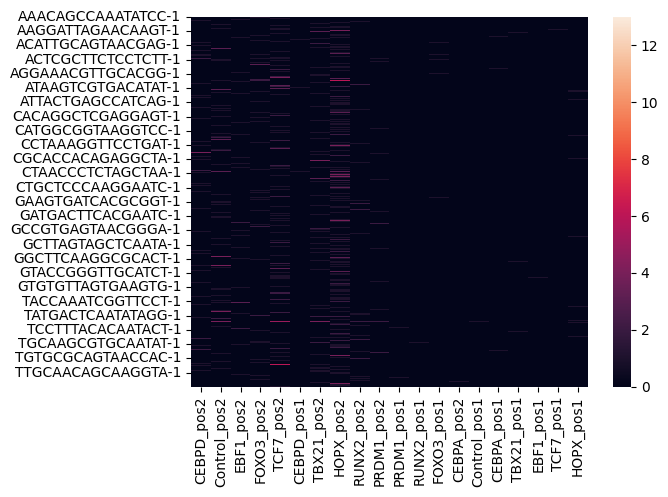

In [15]:
sns.heatmap(barcodes1)

In [16]:
barcodes1.columns

Index(['CEBPD_pos2', 'Control_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'TCF7_pos2',
       'CEBPD_pos1', 'TBX21_pos2', 'HOPX_pos2', 'RUNX2_pos2', 'PRDM1_pos2',
       'PRDM1_pos1', 'RUNX2_pos1', 'FOXO3_pos1', 'CEBPA_pos2', 'Control_pos1',
       'CEBPA_pos1', 'TBX21_pos1', 'EBF1_pos1', 'TCF7_pos1', 'HOPX_pos1'],
      dtype='object')

In [17]:
pos1 = ['Control_pos1', 'CEBPA_pos1', 'CEBPD_pos1', 'EBF1_pos1', 'FOXO3_pos1', 'HOPX_pos1', 'PRDM1_pos1', 'RUNX2_pos1', 'TBX21_pos1', 'TCF7_pos1']

In [18]:
pos2 = ['Control_pos2', 'CEBPA_pos2', 'CEBPD_pos2', 'EBF1_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'PRDM1_pos2', 'RUNX2_pos2', 'TBX21_pos2', 'TCF7_pos2']

## Analyse position 2

In [19]:
barcodes1_pos2 = barcodes1[pos2]

In [20]:
adata = sc.AnnData(barcodes1_pos2)

In [21]:
adata

AnnData object with n_obs × n_vars = 20422 × 10

In [22]:
barcodes1_pos2['max'] = barcodes1_pos2.idxmax(axis=1)

/tmp/ipykernel_3971586/2265420269.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barcodes1_pos2['max'] = barcodes1_pos2.idxmax(axis=1)


In [23]:
sc.pp.scale(adata)

In [24]:
adata.obs['max'] = barcodes1_pos2['max']

In [25]:
adata.obs["perturbation"] = pd.Categorical(
    values=adata.obs['max'], categories=pos2, ordered=True
)

In [26]:
barcodes1_pos2['max'].value_counts()

max
HOPX_pos2       5901
Control_pos2    3413
TCF7_pos2       3324
FOXO3_pos2      1846
TBX21_pos2      1821
CEBPD_pos2      1732
RUNX2_pos2       852
EBF1_pos2        767
PRDM1_pos2       702
CEBPA_pos2        64
Name: count, dtype: int64

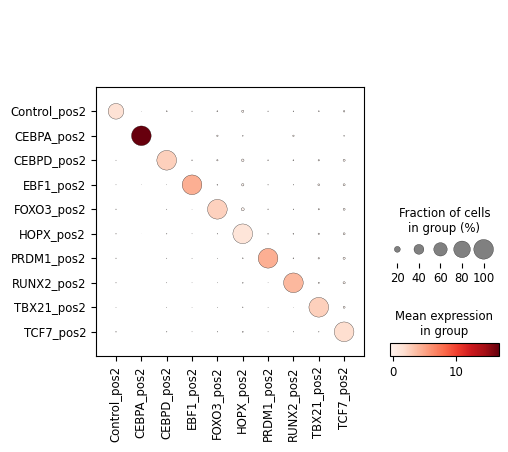

In [27]:
sc.pl.dotplot(adata, var_names=pos2, groupby='perturbation')

In [28]:
sc.pl.DotPlot(adata, var_names=pos2, groupby='perturbation').add_totals()

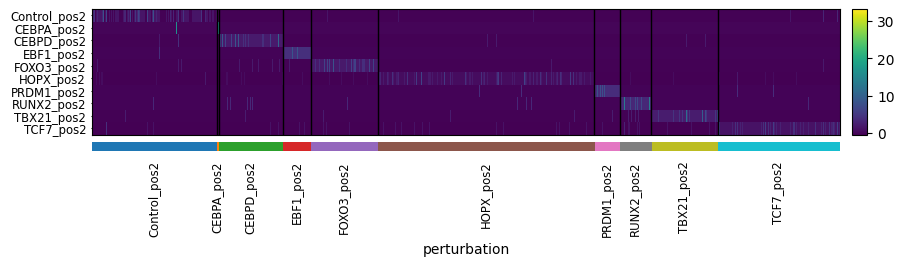

In [29]:
sc.pl.heatmap(adata, pos2, groupby='perturbation', swap_axes=True)

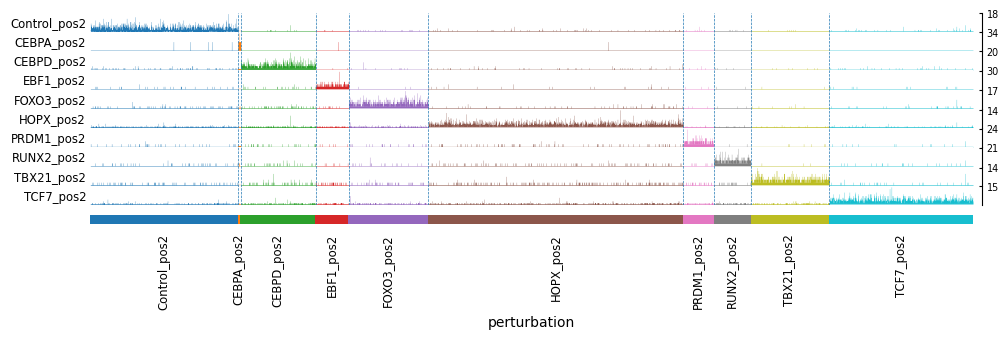

In [30]:
sc.pl.tracksplot(adata, pos2, groupby='perturbation')

## Analyse position 1

In [31]:
barcodes1_pos1 = barcodes1[pos1]

In [32]:
adata = sc.AnnData(barcodes1_pos1)

In [33]:
barcodes1_pos1['max'] = barcodes1_pos1.idxmax(axis=1)

/tmp/ipykernel_3971586/2947119840.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barcodes1_pos1['max'] = barcodes1_pos1.idxmax(axis=1)


In [34]:
barcodes1_pos1['max'].value_counts()

max
Control_pos1    19130
HOPX_pos1         250
RUNX2_pos1        176
TCF7_pos1         158
FOXO3_pos1        140
PRDM1_pos1        137
CEBPD_pos1        129
TBX21_pos1        119
CEBPA_pos1        106
EBF1_pos1          77
Name: count, dtype: int64

In [35]:
adata

AnnData object with n_obs × n_vars = 20422 × 10

In [36]:
sc.pp.scale(adata)

In [37]:
adata.obs['max'] = barcodes1_pos1['max']

In [38]:
adata.obs["perturbation"] = pd.Categorical(
    values=adata.obs['max'], categories=pos1, ordered=True
)

In [39]:
sc.pp.pca(adata)

In [40]:
sc.tl.tsne(adata, n_pcs=10, use_rep='pca', perplexity=100)

ValueError: Did not find pca in `.obsm.keys()`. You need to compute it first.

In [ ]:
sc.pl.tsne(adata, color='perturbation')

In [ ]:
sc.pl.tsne(adata, color=pos1)

In [ ]:
barcodes1_pos1['max'].value_counts()

In [ ]:
sc.pl.dotplot(adata, var_names=pos1, groupby='perturbation')

In [ ]:
sc.pl.DotPlot(adata, var_names=pos1, groupby='perturbation', cmap='Reds').add_totals().show()

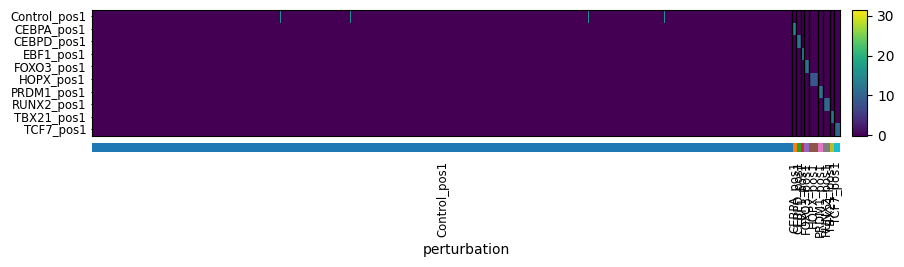

In [41]:
sc.pl.heatmap(adata, pos1, groupby='perturbation', swap_axes=True)

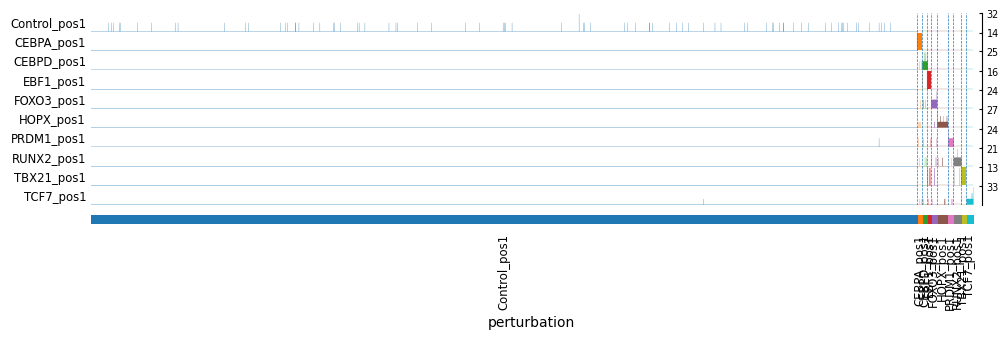

In [42]:
sc.pl.tracksplot(adata, pos1, groupby='perturbation')

## Sample 2

In [43]:
## Read barcodes
barcodes2 = pd.read_csv('/lustre/scratch126/cellgen/teichmann/kp9/od5/25-02-17-transgenes-barcodes-simple/Imm_NK15385852_and_50044_Imm_NK15385636.csv', index_col=0)

In [44]:
barcodes2

,HOPX_pos2,TCF7_pos2,FOXO3_pos2,Control_pos2,CEBPD_pos2,TBX21_pos2,HOPX_pos1,TCF7_pos1
AAACCAACATTGTGAT-1,4,0,0,0,0,0,0,0
AAAGGCTCACATGCTA-1,0,0,1,0,0,0,0,0
AACCTCACACAAGCCT-1,0,2,0,0,0,0,0,0
AAGCCACGTCACAGAC-1,0,1,0,0,0,0,0,0
AAGCCTTAGCAACAAG-1,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...
TTGCAATCACTAGCGT-1,1,0,0,0,0,0,0,0
TTGGATATCCGTGACA-1,1,0,0,0,0,0,0,0
TTGGATCAGCGATAGA-1,3,0,0,0,0,0,0,0
TTTAGGATCATCCTCA-1,0,0,0,0,3,0,0,0


In [45]:
barcodes2.sum(axis=0)

HOPX_pos2        83
TCF7_pos2       112
FOXO3_pos2       19
Control_pos2     11
CEBPD_pos2        9
TBX21_pos2        9
HOPX_pos1         6
TCF7_pos1         2
dtype: int64

In [46]:
barcodes2.sum(axis=1).sort_values(ascending=False).head(60)

TTCCCGCCATGTTGTG-1    11
TTCCTCAAGGCGAAAC-1     6
GTTAAGTGTACCGAAC-1     6
GGCCATCAGTTAGACC-1     6
TCGCGAGGTAACCTAG-1     5
TCCACAACATGCTATG-1     4
CGTGCTGCAATCGCAC-1     4
CCAGGAACATAGACCC-1     4
AAACCAACATTGTGAT-1     4
TCCATCATCTCGCCCA-1     4
TCATGCCTCAATCATG-1     3
GATTAGTGTCCTCCAA-1     3
GTTGGAGCAATTGAGA-1     3
GACCGTTCAAAGGCCA-1     3
GTTAAGTGTGCTTTAC-1     3
TAGGAACCAAGGTATA-1     3
TTGGATCAGCGATAGA-1     3
TTTAGGATCATCCTCA-1     3
TTATCCGTCATAGACC-1     3
CCTACTTCACCTCAGG-1     3
AATCCGTAGTGACCTG-1     3
CCATATTTCCCGAACA-1     3
GGTTGCTCAGAAATGC-1     3
TTCCTTCTCCTTGTTG-1     2
AATGTCCAGGACCTGC-1     2
TTGACATCACAAAGAC-1     2
TCATTTGGTTAACGAT-1     2
TATTAGGTCCTGAATA-1     2
ACTCACTGTCTTTGAC-1     2
TGCAAGCGTGGATTCA-1     2
GTCATTAAGACAAAGT-1     2
GTCTCACTCCCTCGCA-1     2
AGGTTTGGTGTTAGCA-1     2
GTTCGCTTCTCAATTC-1     2
CTTTAGTTCCTTGCAC-1     2
CTGCTATGTGTCCAAA-1     2
GTATTGCAGAAGCTAG-1     2
ATGGTTATCATCCTAT-1     2
GTATGTTCAACTAGGG-1     2
GTAAGCGCAAGGACCA-1     2


<Axes: >

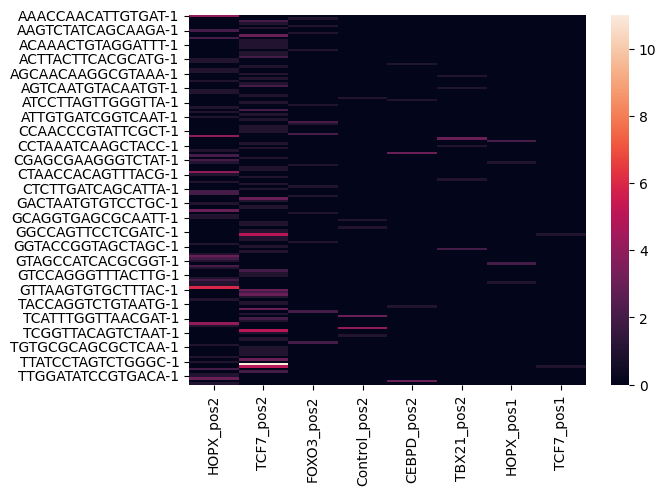

In [47]:
sns.heatmap(barcodes2)

In [48]:
barcodes2.columns

Index(['HOPX_pos2', 'TCF7_pos2', 'FOXO3_pos2', 'Control_pos2', 'CEBPD_pos2',
       'TBX21_pos2', 'HOPX_pos1', 'TCF7_pos1'],
      dtype='object')

In [49]:
pos1 = ['HOPX_pos1', 'TCF7_pos1']

In [50]:
pos2 = ['Control_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'TBX21_pos2', 'TCF7_pos2']

## Analyse position 2

In [51]:
barcodes2_pos2 = barcodes2[pos2]

In [52]:
adata = sc.AnnData(barcodes2_pos2)

In [53]:
barcodes2_pos2['max'] = barcodes2_pos2.idxmax(axis=1)

/tmp/ipykernel_3971586/2710475036.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barcodes2_pos2['max'] = barcodes2_pos2.idxmax(axis=1)


In [54]:
adata

AnnData object with n_obs × n_vars = 154 × 5

In [55]:
sc.pp.scale(adata)

In [56]:
adata.obs['max'] = barcodes2_pos2['max']

In [57]:
adata.obs["perturbation"] = pd.Categorical(
    values=adata.obs['max'], categories=pos2, ordered=True
)

In [58]:
barcodes2_pos2['max'].value_counts()

max
TCF7_pos2       70
HOPX_pos2       50
FOXO3_pos2      15
Control_pos2    13
TBX21_pos2       6
Name: count, dtype: int64

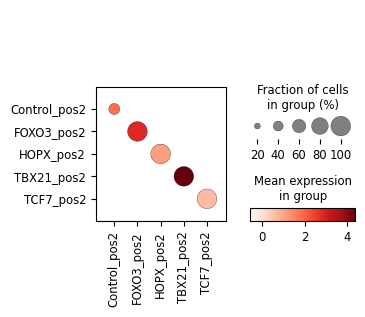

In [59]:
sc.pl.dotplot(adata, var_names=pos2, groupby='perturbation')

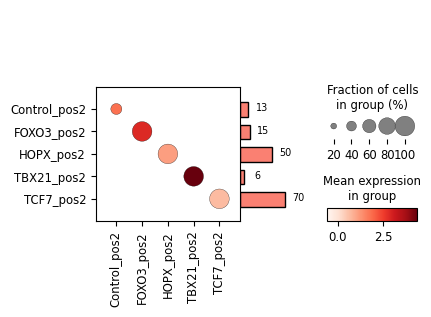

In [60]:
sc.pl.DotPlot(adata, var_names=pos2, groupby='perturbation', cmap='Reds').add_totals().show()

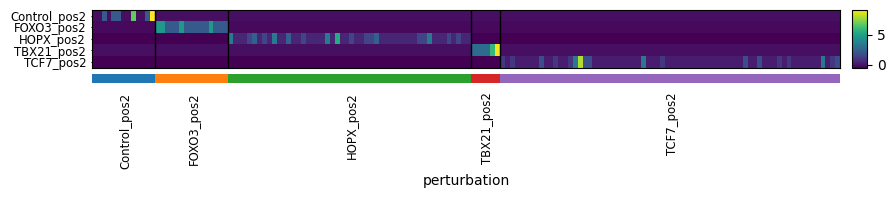

In [61]:
sc.pl.heatmap(adata, pos2, groupby='perturbation', swap_axes=True)

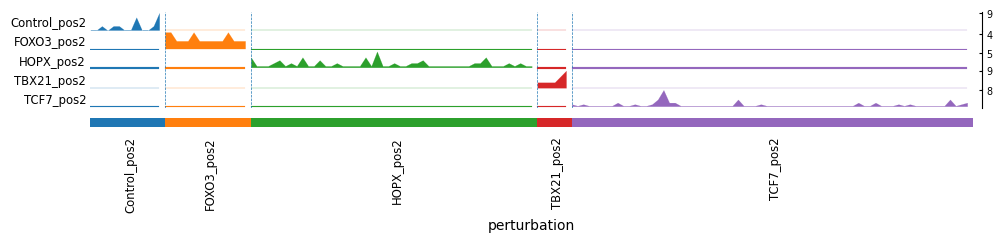

In [62]:
sc.pl.tracksplot(adata, pos2, groupby='perturbation')

## Analyse position 1

In [63]:
barcodes2_pos1 = barcodes2[pos1]

In [64]:
adata = sc.AnnData(barcodes2_pos1)

In [65]:
barcodes2_pos1['max'] = barcodes2_pos1.idxmax(axis=1)

/tmp/ipykernel_3971586/3692451966.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barcodes2_pos1['max'] = barcodes2_pos1.idxmax(axis=1)


In [66]:
barcodes2_pos1['max'].value_counts()

max
HOPX_pos1    152
TCF7_pos1      2
Name: count, dtype: int64

In [67]:
adata

AnnData object with n_obs × n_vars = 154 × 2

In [68]:
sc.pp.scale(adata)

In [69]:
adata.obs['max'] = barcodes2_pos1['max']

In [70]:
adata.obs["perturbation"] = pd.Categorical(
    values=adata.obs['max'], categories=pos1, ordered=True
)

In [71]:
barcodes2_pos1['max'].value_counts()

max
HOPX_pos1    152
TCF7_pos1      2
Name: count, dtype: int64

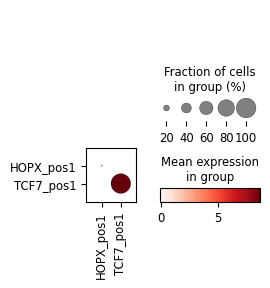

In [72]:
sc.pl.dotplot(adata, var_names=pos1, groupby='perturbation')

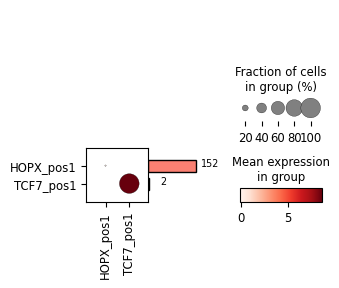

In [73]:
sc.pl.DotPlot(adata, var_names=pos1, groupby='perturbation', cmap='Reds').add_totals().show()

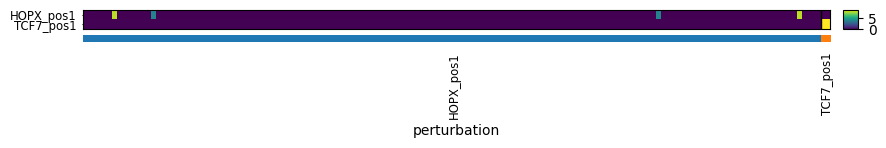

In [74]:
sc.pl.heatmap(adata, pos1, groupby='perturbation', swap_axes=True)

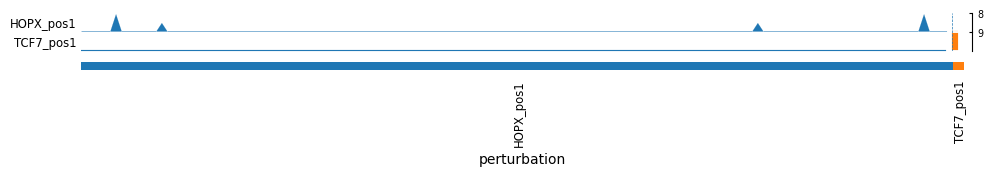

In [75]:
sc.pl.tracksplot(adata, pos1, groupby='perturbation')

## Sample 3

In [76]:
## Read barcodes
barcodes3 = pd.read_csv('/lustre/scratch126/cellgen/teichmann/kp9/od5/25-02-17-transgenes-barcodes-simple/Imm_NK15385853_and_50044_Imm_NK15385637.csv', index_col=0)

In [77]:
barcodes3

,HOPX_pos2,TCF7_pos2,CEBPD_pos2,FOXO3_pos2,TBX21_pos2,Control_pos2,CEBPD_pos1,TCF7_pos1,HOPX_pos1,FOXO3_pos1,TBX21_pos1,Control_pos1
AAACAGCCACGAACAG-1,1,0,0,0,0,0,0,0,0,0,0,0
AAACAGCCAGGTTATT-1,0,1,0,0,0,0,0,0,0,0,0,0
AAACATGCAATGAAGC-1,0,1,0,0,0,0,0,0,0,0,0,0
AAACATGCACTTCATC-1,0,0,0,0,1,0,0,0,0,0,0,0
AAACATGCATGAGCAG-1,1,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTCTAGCTTCCCG-1,0,0,1,0,0,0,0,0,0,0,0,0
TTTGTGAAGCTGGCTA-1,0,1,0,0,0,0,0,0,0,0,0,0
TTTGTGGCAGCATTAT-1,0,0,1,0,0,0,0,0,0,0,0,0
TTTGTGGCATGAATAG-1,0,0,0,0,1,0,0,0,0,0,0,0


In [78]:
barcodes3.sum(axis=0)

HOPX_pos2       602
TCF7_pos2       958
CEBPD_pos2      268
FOXO3_pos2      303
TBX21_pos2      256
Control_pos2     46
CEBPD_pos1        2
TCF7_pos1         9
HOPX_pos1         6
FOXO3_pos1        7
TBX21_pos1        3
Control_pos1      1
dtype: int64

In [79]:
barcodes3.sum(axis=1).sort_values(ascending=False).head(60)

AGGTACGCAGGTATTT-1    11
AGTTTGCAGGAGCACG-1     9
CCATAAATCAATAGCC-1     8
GCTTGTTGTCTAGCTT-1     8
AATTCGTCAACAACAA-1     8
TCCGCCATCGGGCCAT-1     7
TTTGACCGTCAAGACC-1     6
GTGCTTACAAATATCC-1     6
GAGCTTGTCTTGTCCA-1     6
ATGGTCTAGCACTAGT-1     6
CATCCTTCAGCTAACC-1     6
TGGCGGTTCGATTTGA-1     5
GGAGCGATCTACCTCA-1     5
CACTTAAAGTCATTAG-1     5
TTAGACTCAAACATAG-1     5
GATTCCTGTGTTTCAC-1     5
CGTGAGGAGCTTGCTC-1     5
CTAGTAATCCAATAGC-1     5
TTCTTAGGTACTTCAC-1     5
GAGAACCAGAAGCTAG-1     4
CTGAAACTCCCTGGAA-1     4
CACTGACCATTCCTGT-1     4
CTGGTTACACATACTG-1     4
AGGTTTGGTATTGTGG-1     4
GCGTTTCTCGTTACAA-1     4
CGCATGATCAATTGGC-1     4
CTTAATGAGCTCCCTG-1     4
TCCATGCTCCTCAGTC-1     4
ACCAAACTCACTCGCT-1     4
ATGCATTCAAGCGAGC-1     4
ATGACGAAGGACTAAG-1     4
ATCATCAAGTCAATTG-1     4
ACAGGCTGTTCCGCAC-1     4
GGTCAAGCAGGCATCT-1     4
CCAGGATGTACTGAAT-1     4
GTCATCACAATTTGGT-1     4
TGAGCACGTTCTTTAG-1     4
GAGTCATTCTAGCTAA-1     4
AGAAACCCATGTTGTG-1     4
CTCAATAAGCAAGACA-1     4


<Axes: >

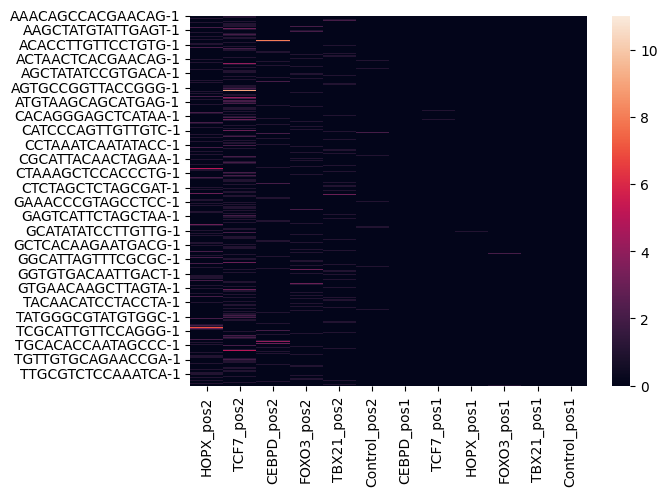

In [80]:
sns.heatmap(barcodes3)

In [81]:
barcodes3.columns

Index(['HOPX_pos2', 'TCF7_pos2', 'CEBPD_pos2', 'FOXO3_pos2', 'TBX21_pos2',
       'Control_pos2', 'CEBPD_pos1', 'TCF7_pos1', 'HOPX_pos1', 'FOXO3_pos1',
       'TBX21_pos1', 'Control_pos1'],
      dtype='object')

In [82]:
pos1 = ['Control_pos1', 'CEBPD_pos1', 'FOXO3_pos1', 'HOPX_pos1', 'TBX21_pos1', 'TCF7_pos1']

In [83]:
pos2 = ['Control_pos2', 'CEBPD_pos2', 'FOXO3_pos2', 'HOPX_pos2', 'TBX21_pos2', 'TCF7_pos2']

## Analyse position 2

In [84]:
barcodes3_pos2 = barcodes3[pos2]

In [85]:
adata = sc.AnnData(barcodes3_pos2)

In [86]:
barcodes3_pos2['max'] = barcodes3_pos2.idxmax(axis=1)

/tmp/ipykernel_3971586/3084934476.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barcodes3_pos2['max'] = barcodes3_pos2.idxmax(axis=1)


In [87]:
adata

AnnData object with n_obs × n_vars = 1911 × 6

In [88]:
sc.pp.scale(adata)

In [89]:
adata.obs['max'] = barcodes3_pos2['max']

In [90]:
adata.obs["perturbation"] = pd.Categorical(
    values=adata.obs['max'], categories=pos2, ordered=True
)

In [91]:
barcodes3_pos2['max'].value_counts()

max
TCF7_pos2       738
HOPX_pos2       465
FOXO3_pos2      249
TBX21_pos2      207
CEBPD_pos2      195
Control_pos2     57
Name: count, dtype: int64

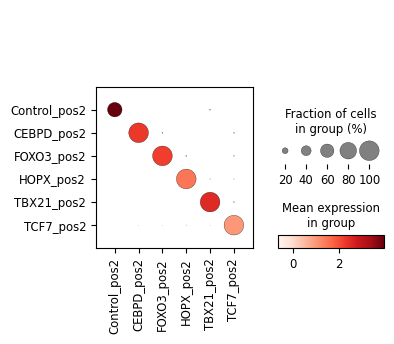

In [92]:
sc.pl.dotplot(adata, var_names=pos2, groupby='perturbation')

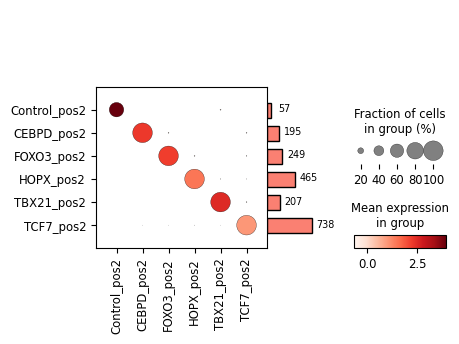

In [93]:
sc.pl.DotPlot(adata, var_names=pos2, groupby='perturbation', cmap='Reds').add_totals().show()

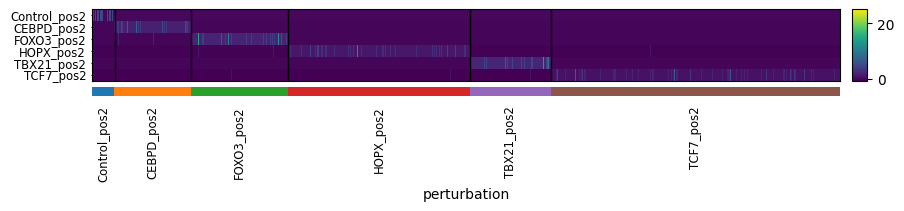

In [94]:
sc.pl.heatmap(adata, pos2, groupby='perturbation', swap_axes=True)

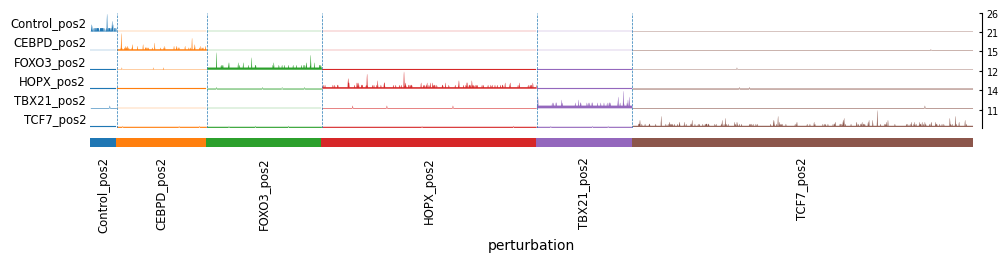

In [95]:
sc.pl.tracksplot(adata, pos2, groupby='perturbation')

## Analyse position 1

In [96]:
barcodes3_pos1 = barcodes3[pos1]

In [97]:
adata = sc.AnnData(barcodes3_pos1)

In [98]:
barcodes3_pos1['max'] = barcodes3_pos1.idxmax(axis=1)

/tmp/ipykernel_3971586/120475095.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barcodes3_pos1['max'] = barcodes3_pos1.idxmax(axis=1)


In [99]:
barcodes3_pos1['max'].value_counts()

max
Control_pos1    1886
TCF7_pos1          8
HOPX_pos1          6
FOXO3_pos1         6
TBX21_pos1         3
CEBPD_pos1         2
Name: count, dtype: int64

In [100]:
adata

AnnData object with n_obs × n_vars = 1911 × 6

In [101]:
sc.pp.scale(adata)

In [102]:
adata.obs['max'] = barcodes3_pos1['max']

In [103]:
adata.obs["perturbation"] = pd.Categorical(
    values=adata.obs['max'], categories=pos1, ordered=True
)

In [104]:
barcodes3_pos1['max'].value_counts()

max
Control_pos1    1886
TCF7_pos1          8
HOPX_pos1          6
FOXO3_pos1         6
TBX21_pos1         3
CEBPD_pos1         2
Name: count, dtype: int64

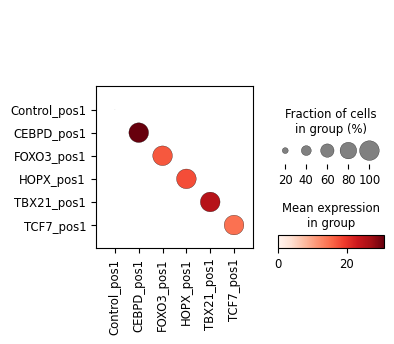

In [105]:
sc.pl.dotplot(adata, var_names=pos1, groupby='perturbation')

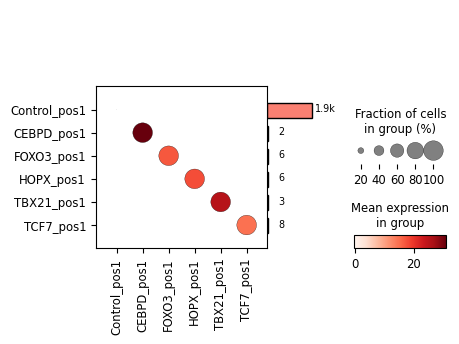

In [106]:
sc.pl.DotPlot(adata, var_names=pos1, groupby='perturbation', cmap='Reds').add_totals().show()

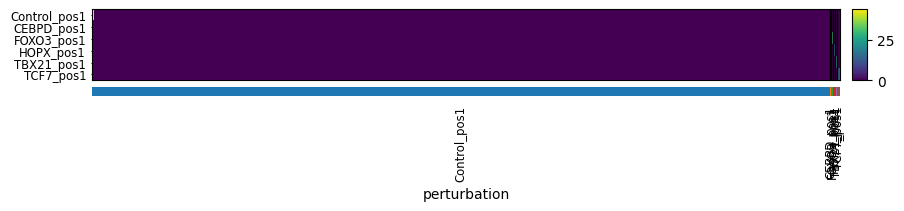

In [107]:
sc.pl.heatmap(adata, pos1, groupby='perturbation', swap_axes=True)

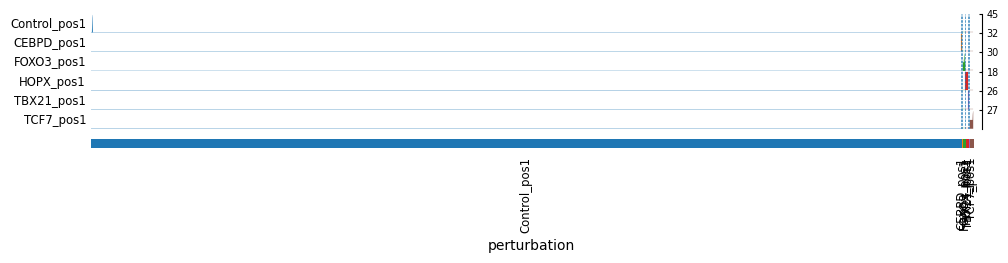

In [108]:
sc.pl.tracksplot(adata, pos1, groupby='perturbation')

In [109]:
## Save files
import re

In [110]:
barcodes1_pos2['perturbation'] = [re.sub('_pos2', '', x) for x in barcodes1_pos2['max']]

/tmp/ipykernel_3971586/3536702987.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barcodes1_pos2['perturbation'] = [re.sub('_pos2', '', x) for x in barcodes1_pos2['max']]


In [111]:
barcodes2_pos2['perturbation'] = [re.sub('_pos2', '', x) for x in barcodes2_pos2['max']]

/tmp/ipykernel_3971586/1741710395.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barcodes2_pos2['perturbation'] = [re.sub('_pos2', '', x) for x in barcodes2_pos2['max']]


In [112]:
barcodes3_pos2['perturbation'] = [re.sub('_pos2', '', x) for x in barcodes3_pos2['max']]

/tmp/ipykernel_3971586/4034126849.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  barcodes3_pos2['perturbation'] = [re.sub('_pos2', '', x) for x in barcodes3_pos2['max']]


In [113]:
barcodes1_pos2.to_csv(work_dir + 'Imm_NK15385635.csv')

In [114]:
barcodes2_pos2.to_csv(work_dir + 'Imm_NK15385636.csv')

In [115]:
barcodes3_pos2.to_csv(work_dir + 'Imm_NK15385637.csv')